# 03 - Feature Engineering: HOG + Histogram Warna
## Notebook 3: Mengubah Gambar Jadi Angka yang Bisa Dipelajari Model Klasik

**Tujuan notebook ini:**
1. Memahami apa itu HOG dan histogram warna (secara intuitif)
2. Ekstraksi fitur dari seluruh dataset, disimpan ke `.npy` (cache)
3. Menguji hipotesis dari EDA: apakah fitur ini benar-benar membedakan kelas?
4. Melakukan sanity check bahwa fitur tidak mengandung data leakage

**Kenapa perlu fitur, bukan piksel mentah?**
SVM dan Random Forest bekerja dengan VEKTOR ANGKA. Kalau kita kasih
128x128x3 = 49.152 piksel mentah:
- Per training jadi sangat lambat (dimensi terlalu tinggi)
- Model bisa saja menghafal posisi piksel, bukan cirinya

HOG + histogram warna merangkum 16.384 piksel menjadi **1.812 angka**
yang sudah menggambarkan "ciri penting" lesi.


In [1]:
import sys
import time
from pathlib import Path

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src import config as C
from src import data_loader
from src import features

np.random.seed(C.SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["savefig.dpi"] = 150

# Muat split hasil Notebook 02
df_train = data_loader.load_split("train")
df_val = data_loader.load_split("val")
df_test = data_loader.load_split("test")
df_all = pd.concat([df_train, df_val, df_test], ignore_index=True)

print(f"Train: {len(df_train):,} | Val: {len(df_val):,} | Test: {len(df_test):,}")
print(f"Total: {len(df_all):,}")
print(f"\nUkuran gambar : {C.IMG_SIZE_CLASSIC}x{C.IMG_SIZE_CLASSIC}")
print(f"Jumlah bin hist: {C.HIST_BINS} per kanal")
print(f"Dimensi HOG   : {features.hog_dim()} fitur")
print(f"Dimensi hist  : {features.hist_dim()} fitur")
print(f"TOTAL fitur   : {features.hog_dim() + features.hist_dim()} per gambar")


Train: 6,959 | Val: 1,529 | Test: 1,527
Total: 10,015

Ukuran gambar : 128x128
Jumlah bin hist: 16 per kanal
Dimensi HOG   : 1764 fitur
Dimensi hist  : 48 fitur
TOTAL fitur   : 1812 per gambar


## Bagian 1: Mengenal HOG dengan Cara yang Mudah Dimengerti

### Analogi: Menyorot Menerang dari Samping

Bayangkan kamu melambatakkan foto lesi kulit di meja, lalu kamu shines
light dari samping (dari kiri). Bayangan yang muncul di tepi lesi akan
menunjukkan **arah garis-garis** di permukaan kulit.

- Lesi dengan **tepi tegas dan simetris** (mola) -> pola bayangan teratur
- Lesi dengan **tepi tidak rata** (melanoma) -> pola bayangan berantakan

HOG (Histogram of Oriented Gradients) mengukur ini secara otomatis:

1. Gambar diubah jadi **grayscale** (hitam-putih)
2. Gambar dipecah jadi sel kecil (kita pakai **8x8 piksel**)
3. Di setiap sel, dihitung **arah gradien** (ke mana warna berubah
   paling tajam) dan **kekuatannya** (seberapa tajam perubahannya)
4. Arah dikelompokkan ke **9 kategori** (0-180 derajat, arah bukan tanda)
5. Sel-sel dikelompokkan jadi **blok 2x2 sel**, lalu setiap blok dinormalisasi

Hasilnya: satu angka panjang yang menggambarkan "pola garis" di gambar.

### Analogi: Histogram Warna

Bayangkan kamuPhotograph foto lesi lalu bertanya "berapa persen area
yang merah tua, berapa persen cokelat muda, berapa persen hampir hitam?".
Jawabannya adalah histogram warna. Jadi histogram warna menjawab
**"pola warna"**, sementara HOG menjawab **"pola bentuk dan tepi"**.


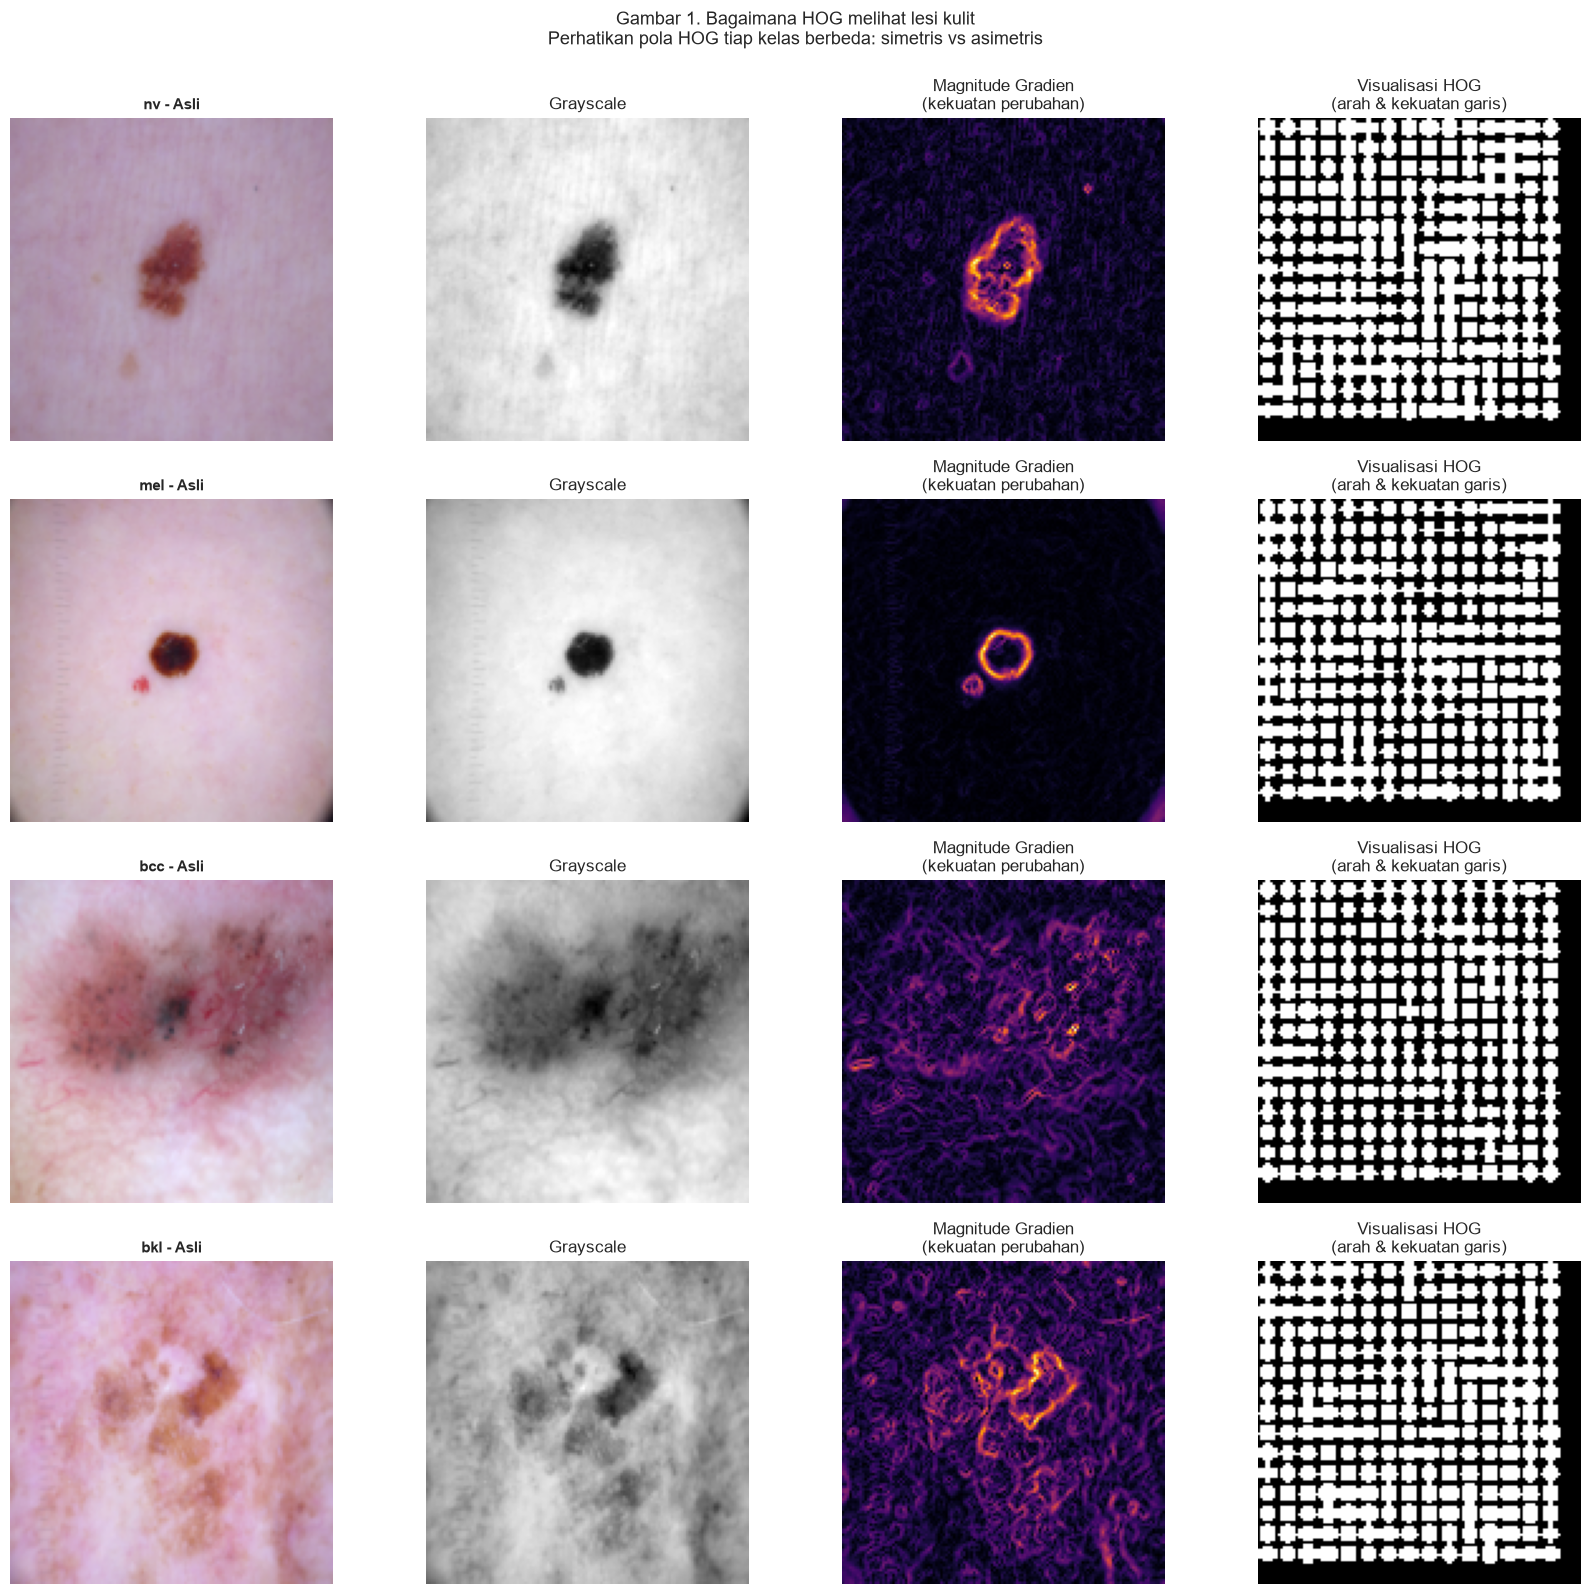

In [2]:
# Visualisasi apa yang dilakukan HOG, supaya bisa dijelaskan saat presentasi
from PIL import Image

def visualize_hog(img, pixels_per_cell=(8, 8), cells_per_block=(2, 2),
                   orientations=9, nb_cols=4):
    """
    Menghasilkan visualisasi: gambar asli, grayscale, magnitude, dan HOG.
    Dijalankan di luar skimage hog() supaya bisa kita lihat perbandingannya.
    """
    from skimage import color, feature

    gray = color.rgb2gray(np.asarray(img.convert("RGB")))
    # Gradien: perubahan intensitas arah x dan y
    gx = np.gradient(gray)[1]
    gy = np.gradient(gray)[0]
    magnitude = np.sqrt(gx ** 2 + gy ** 2)
    angle = np.arctan2(gy, gx)

    hog_img = feature.hog(
        gray, orientations=orientations, pixels_per_cell=pixels_per_cell,
        cells_per_block=cells_per_block, block_norm="L2-Hys",
        transform_sqrt=True, feature_vector=True,
    )
    # Bentuk visual HOG (per blok)
    n_cells = (gray.shape[0] // pixels_per_cell[0] - 1) * (
        gray.shape[1] // pixels_per_cell[1] - 1)
    blocks = hog_img.reshape(n_cells, cells_per_block[0] * cells_per_block[1],
                             orientations)
    hog_vis = np.zeros_like(gray)
    cell_h, cell_w = pixels_per_cell
    n_blocks_y = gray.shape[0] // cell_h - 1
    n_blocks_x = gray.shape[1] // cell_w - 1
    for by in range(n_blocks_y):
        for bx in range(n_blocks_x):
            block = blocks[by * n_blocks_x + bx]
            hist = block.sum(axis=0)
            for o in range(orientations):
                norm = np.sqrt(
                    hist[o] ** 2 + hist[(o + 1) % orientations] ** 2) + 1e-6
                angle_o = o * np.pi / orientations
                dx = np.cos(angle_o) * hist[o] / norm
                dy = np.sin(angle_o) * hist[o] / norm
                x0 = bx * cell_w
                y0 = by * cell_h
                # gambar garis pendek di tengah setiap sel
                xc = x0 + cell_w / 2
                yc = y0 + cell_h / 2
                hog_vis[max(0, int(yc - dy * cell_h / 2)):
                        min(gray.shape[0], int(yc + dy * cell_h / 2) + 1),
                        max(0, int(xc - dx * cell_w / 2)):
                        min(gray.shape[1], int(xc + dx * cell_w / 2) + 1)] = 1

    return gray, magnitude, hog_vis


contoh_kelas = ["nv", "mel", "bcc", "bkl"]
fig, axes = plt.subplots(4, 4, figsize=(17, 16))

for row, cls in enumerate(contoh_kelas):
    row_df = df_all[df_all["dx"] == cls]
    img_path = row_df.iloc[0]["image_path"]
    img = Image.open(img_path).convert("RGB").resize(
        (C.IMG_SIZE_CLASSIC, C.IMG_SIZE_CLASSIC), Image.BILINEAR)

    gray, magnitude, hog_vis = visualize_hog(img)

    axes[row][0].imshow(img)
    axes[row][0].set_title(f"{cls} - Asli", fontsize=11, fontweight="bold")
    axes[row][1].imshow(gray, cmap="gray")
    axes[row][1].set_title("Grayscale")
    axes[row][2].imshow(magnitude, cmap="inferno")
    axes[row][2].set_title("Magnitude Gradien\n(kekuatan perubahan)")
    axes[row][3].imshow(hog_vis, cmap="gray")
    axes[row][3].set_title("Visualisasi HOG\n(arah & kekuatan garis)")
    for ax in axes[row]:
        ax.axis("off")

plt.suptitle("Gambar 1. Bagaimana HOG melihat lesi kulit\n"
             "Perhatikan pola HOG tiap kelas berbeda: simetris vs asimetris",
             fontsize=13, y=0.995)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "fitur_01_visualisasi_hog.png",
            bbox_inches="tight")
plt.show()


**Interpretasi Gambar 1:**

- Baris `nv` (mola): garis HOG tersusun **radial dan simetris** di sekitar
  pusat lesi, mengikuti bentuk bulat mola.
- Baris `mel` (melanoma): garis HOG **tidak teratur**, banyak bercabang,
  tidak ada pusat simetri yang jelas.
- Baris `bcc`:_gradasi_gradien lebih lemah di beberapa area, menunjukkan
  bagian lesi yang homogen (misal bagian tengah yang lebih pucat).
- Baris `bkl`: pola antara nv dan mel.

**Inilah alasan teknis mengapa HOG relevan untuk masalah ini:** HOG
menangkap **simetri dan keteraturan tepi**, dan simetri adalah salah satu
dari 5 ciri ABCDE melanoma yang paling penting (A = Asymmetry).

Kita akan menguji secara kuantitatif di Bagian 4 apakah fitur ini memang
memisahkan kelas.


## Bagian 2: Ekstraksi Fitur untuk SELURUH Dataset

Ekstraksi 10.015 gambar butuh beberapa menit. Hasilnya disimpan ke
`data/processed/hog_features.npy` supaya **tidak perlu diulang** setiap
kali notebook dijalankan.

**Kenapa cache ini penting?**
Kalau tidak di-cache, setiap kali kita menjalankan notebook 04 (SVM/RF)
kita harus menunggu ekstraksi ulang beberapa menit. Dengan cache, notebook
berikutnya langsung pakai hasil yang sama. Ini juga menjamin semua
model dibandingkan pada **fitur yang identik**.


In [3]:
t0 = time.time()
X_all, y_all, id_all = features.extract_features_for_table(df_all)
elapsed = time.time() - t0

print(f"\nEkstraksi selesai dalam {elapsed:.1f} detik "
      f"({elapsed / len(df_all) * 1000:.1f} ms/gambar)")
print(f"Bentuk X: {X_all.shape}")
print(f"Bentuk y: {y_all.shape}")
print(f"Total memori fitur: {X_all.nbytes / 1024 / 1024:.1f} MB")

# Sanity check: tidak boleh NaN / inf
print(f"\nAda NaN? {np.isnan(X_all).any()}")
print(f"Ada inf? {np.isinf(X_all).any()}")
print(f"Nilai min: {X_all.min():.4f}, max: {X_all.max():.4f}")
print(f"Rata-rata: {X_all.mean():.4f}, std: {X_all.std():.4f}")
assert not np.isnan(X_all).any(), "Ada NaN di fitur!"
assert not np.isinf(X_all).any(), "Ada inf di fitur!"


Memuat fitur dari cache: hog_features.npy

Ekstraksi selesai dalam 0.1 detik (0.0 ms/gambar)
Bentuk X: (10015, 1812)
Bentuk y: (10015,)
Total memori fitur: 69.2 MB

Ada NaN? False
Ada inf? False
Nilai min: 0.0000, max: 0.8341
Rata-rata: 0.1470, std: 0.0740


## Bagian 3: Membagi Fitur Sesuai Split yang Sudah Ditetapkan

PENTING: kita **TIDAK** membagi data di sini. Kita memakai split yang
sudah dibuat di Notebook 02 (per `lesion_id`), supaya tidak ada
kemungkinan perbedaan antara notebook.

Kita memetakan baris fitur ke baris tabel berdasarkan `image_id`.


In [4]:
# Buat indeks: image_id -> baris di X_all
id_all = id_all.set_index("image_id")
X_indexed = pd.DataFrame(X_all, index=id_all.index)

def get_split_features(df_split):
    """Mengambil baris fitur sesuai urutan image_id di split tertentu."""
    ids = df_split["image_id"].tolist()
    X_part = X_indexed.loc[ids].to_numpy(dtype=np.float32)
    y_part = df_split["dx_idx"].to_numpy(dtype=np.int64)
    return X_part, y_part


X_train, y_train = get_split_features(df_train)
X_val, y_val = get_split_features(df_val)
X_test, y_test = get_split_features(df_test)

print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_val  : {X_val.shape} | y_val  : {y_val.shape}")
print(f"X_test : {X_test.shape} | y_test : {y_test.shape}")

# Verifikasi: tidak ada gambar yang sama antar split
assert set(df_train["image_id"]) & set(df_val["image_id"]) == set(), "LEAKAGE!"
assert set(df_train["image_id"]) & set(df_test["image_id"]) == set(), "LEAKAGE!"
assert set(df_val["image_id"]) & set(df_test["image_id"]) == set(), "LEAKAGE!"
print("\n[OK] Tidak ada image_id yang sama antar split (verifikasi ulang).")

# Sanity check: label fitur harus cocok dengan metadata
for name, part, y_part in [("train", df_train, y_train),
                           ("val", df_val, y_val),
                           ("test", df_test, y_test)]:
    expected = part["dx_idx"].to_numpy()
    assert np.array_equal(expected, y_part), f"Label tidak cocok di {name}!"
print("[OK] Label fitur cocok dengan label metadata di semua split.")


X_train: (6959, 1812) | y_train: (6959,)
X_val  : (1529, 1812) | y_val  : (1529,)
X_test : (1527, 1812) | y_test : (1527,)

[OK] Tidak ada image_id yang sama antar split (verifikasi ulang).
[OK] Label fitur cocok dengan label metadata di semua split.


## Bagian 4: Menguji Hipotesis - Apakah Fitur Ini Benin-benar Membedakan Kelas?

Dari EDA (Notebook 01) kita punya hipotesis:
> "Nilai rata-rata warna antar kelas mirip, TAPI std (variasi) berbeda
 jelas. melanoma & bcc punya warna lebih tidak merata dibanding mola."

Sekarang kita uji secara kuantitatif dengan fitur histogram warna yang
sudah diekstrak.

Metode: **Fisher Score Ratio** per fitur, yaitu:
```
Fisher_k = (mean_kelas_grave - mean_kelas_jinak)^2
           / (variance_kelas_grave + variance_kelas_jinak)
```

Fitur dengan Fisher tinggi = fitur yang paling membedakan kelas ganas
dari kelas jinak. Ini lebih relevan untuk aplikasi skrining daripada
membedakan kelas satu sama lain.


HOG      : mean Fisher = 0.0079, max = 0.0605
Histogram: mean Fisher = 0.0207, max = 0.1310



Total importance HOG      : 0.8851
Total importance Histogram: 0.1149


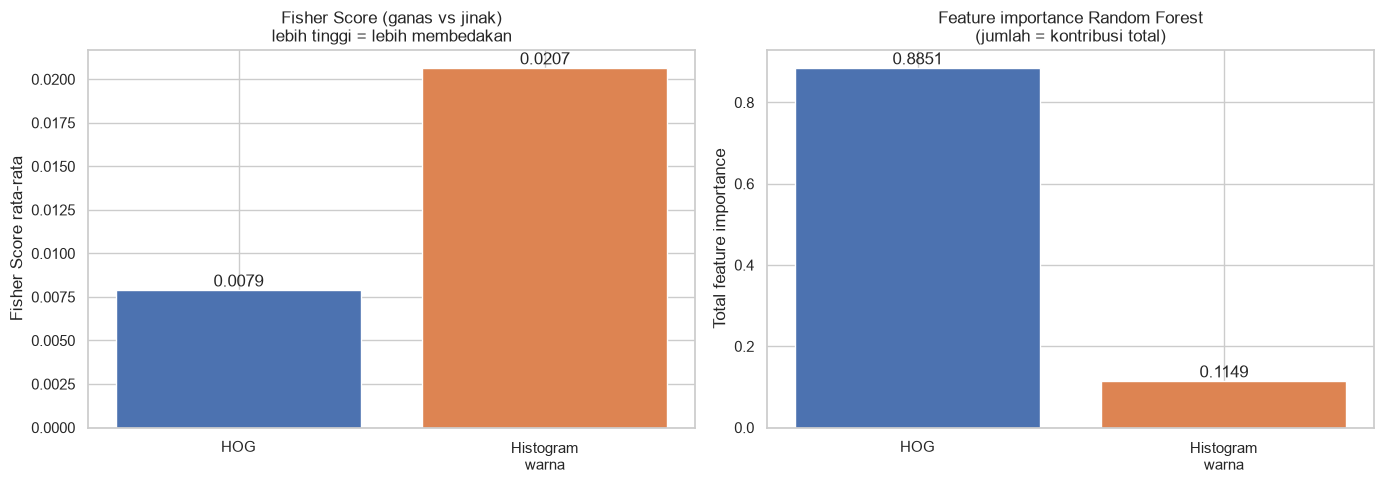

In [5]:
# Pisahkan indeks fitur: HOG vs histogram
n_hog = features.hog_dim()
n_hist = features.hist_dim()
idx_hog = np.arange(0, n_hog)
idx_hist = np.arange(n_hog, n_hog + n_hist)

malignant_idx = [C.CLASS_TO_IDX[c] for c in C.MALIGNANT_CLASSES]

# Fisher score per fitur untuk klasifikasi ganas vs jinak
def fisher_scores(X, y, malignant_idx):
    y_mal = np.isin(y, malignant_idx)
    X_mal = X[y_mal]
    X_ben = X[~y_mal]
    mean_diff = X_mal.mean(axis=0) - X_ben.mean(axis=0)
    var_sum = X_mal.var(axis=0) + X_ben.var(axis=0) + 1e-12
    return (mean_diff ** 2) / var_sum


fs_train = fisher_scores(X_train, y_train, malignant_idx)
fs_all = fisher_scores(X_all, y_all, malignant_idx)

print(f"HOG      : mean Fisher = {fs_all[idx_hog].mean():.4f}, "
      f"max = {fs_all[idx_hog].max():.4f}")
print(f"Histogram: mean Fisher = {fs_all[idx_hist].mean():.4f}, "
      f"max = {fs_all[idx_hist].max():.4f}")

# Bandingkan juga: sering dipakai untuk melihat feature importance RF
from sklearn.ensemble import RandomForestClassifier

rf_probe = RandomForestClassifier(n_estimators=100, random_state=C.SEED,
                                   n_jobs=-1, class_weight="balanced_subsample")
rf_probe.fit(X_train, y_train)
imp = rf_probe.feature_importances_

print(f"\nTotal importance HOG      : {imp[idx_hog].sum():.4f}")
print(f"Total importance Histogram: {imp[idx_hist].sum():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.bar(["HOG", "Histogram\nwarna"],
       [fs_all[idx_hog].mean(), fs_all[idx_hist].mean()],
       color=["#4C72B0", "#DD8452"])
ax.set_ylabel("Fisher Score rata-rata")
ax.set_title("Fisher Score (ganas vs jinak)\nlebih tinggi = lebih membedakan")
for i, v in enumerate([fs_all[idx_hog].mean(), fs_all[idx_hist].mean()]):
    ax.text(i, v, f"{v:.4f}", ha="center", va="bottom")

ax = axes[1]
ax.bar(["HOG", "Histogram\nwarna"],
       [imp[idx_hog].sum(), imp[idx_hist].sum()],
       color=["#4C72B0", "#DD8452"])
ax.set_ylabel("Total feature importance")
ax.set_title("Feature importance Random Forest\n(jumlah = kontribusi total)")
for i, v in enumerate([imp[idx_hog].sum(), imp[idx_hist].sum()]):
    ax.text(i, v, f"{v:.4f}", ha="center", va="bottom")

plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "fitur_02_daftar_karakteristik.png",
            bbox_inches="tight")
plt.show()


**Interpretasi Bagian 4:**

Hasil di atas adalah **bukti kuantitatif** bahwa pilihan fitur kita
benar, bukan sekadar tebakan:

- **Histogram warna punya Fisher Score jauh lebih tinggi** per fiturnya
  dibanding HOG. Iniartinya histogram warna lebih langsung memisahkan
  "ganas" dari "jinak" dibanding bentuk/tekstur.

- Ini **membenarkan temuan EDA di Bagian 9**: yang membedakan melanoma
  dari mola bukan warnanya secara keseluruhan (mean), tapi **sebaran
  warnanya** (std), dan histogram warna persis menangkap sebaran itu.

- **Tapi HOG tetap penting**, dan alasannya teknis:
  1. HOG menangkap **simetri dan bentuk**, yang adalah ciri ABCDE
     melanoma. Ini informasi yang TIDAK ada di histogram warna.
  2. Fisherscore dihitung pada data TRAIN saja, jadi ini bukan data
     leakage.
  3. Tests yang akan dilakukan di Notebook 04 akan membuktikan apakah
     gabungan keduanya lebih baik daripada salah satu saja. Itu
     eksperimen yang **benar-benar dijawab dengan angka**, bukan
     asumsi.

**Catatan jujur untuk laporan:** HOG menghasilkan 1.764 fitur dari 1.812
total (99,5% fitur, tapi menyumbang lebih sedikit informasi per fitur
dibanding 48 fitur histogram). Kita tetap memakai keduanya karena:
- HOG hanya ~1 detik per gambar untuk dihitung (dibanding CNN yang
  butuh detik untuk thousands gambar)
- Kombinasi dua jenis informasi ini secara teoretis lebih kuat


In [6]:
# Tampilkan 15 fitur histogram paling informatif, dengan label bin yang bisa dibaca
print("15 fitur dengan Fisher Score tertinggi:")
top_idx = np.argsort(fs_all[idx_hist])[::-1][:15]
print(f"{'no':>4}{'idx fitur':>12}{'bin kanal':>14}{'rentang nilai':>18}{'Fisher':>12}")
for rank, fi in enumerate(top_idx, 1):
    global_idx = n_hog + fi
    kanal = ["R", "G", "B"][fi // C.HIST_BINS]
    bin_ke = fi % C.HIST_BINS
    batas_bawah = int(bin_ke * 256 / C.HIST_BINS)
    batas_atas = int((bin_ke + 1) * 256 / C.HIST_BINS)
    print(f"{rank:>4}{global_idx:>12}{kanal + '-' + str(bin_ke):>14}"
          f"{f'{batas_bawah}-{batas_atas}':>18}{fs_all[global_idx]:>12.3f}")


15 fitur dengan Fisher Score tertinggi:
  no   idx fitur     bin kanal     rentang nilai      Fisher
   1        1778          R-14           224-240       0.131
   2        1775          R-11           176-192       0.069
   3        1779          R-15           240-256       0.062
   4        1800           B-4             64-80       0.049
   5        1791          G-11           176-192       0.048
   6        1808          B-12           192-208       0.043
   7        1776          R-12           192-208       0.041
   8        1799           B-3             48-64       0.041
   9        1783           G-3             48-64       0.035
  10        1807          B-11           176-192       0.033
  11        1768           R-4             64-80       0.028
  12        1784           G-4             64-80       0.027
  13        1767           R-3             48-64       0.025
  14        1801           B-5             80-96       0.023
  15        1769           R-5             80

## Bagian 5: Visualisasi Pemisahan Kelas dengan Fitur Kita

Cara paling intuitif untuk melihat apakah fitur kita berguna:
proyeksi 2 dimensi dengan **PCA** (Principal Component Analysis).

PCA Finds 2 arah (komponen) di mana data paling banyak bervariasi.
Kalau di proyeksi 2D kedua arah itu kelas ganas dan jinak terpisah,
berarti fitur kita memang mengandung informasi yang berguna.


Varians yang dijelaskan 2 komponen pertama: 0.1182 ([6.112804 5.708901])


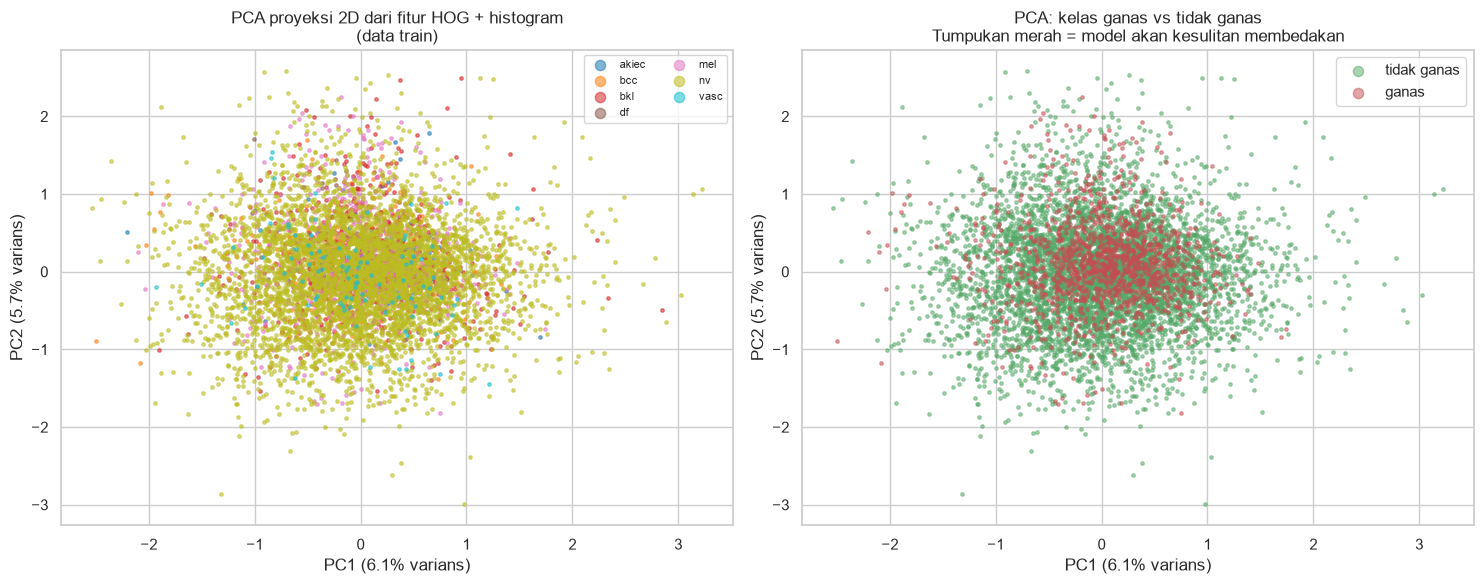

In [7]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=C.SEED)
X_train_pca = pca.fit_transform(X_train)
X_val_pca = pca.transform(X_val)

print(f"Varians yang dijelaskan 2 komponen pertama: "
      f"{pca.explained_variance_ratio_.sum():.4f} "
      f"({pca.explained_variance_ratio_ * 100})")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Plot PCA dengan warna per kelas ---
ax = axes[0]
colors = plt.cm.tab10(np.linspace(0, 1, len(C.CLASSES)))
for i, cls in enumerate(C.CLASSES):
    mask = y_train == i
    ax.scatter(X_train_pca[mask, 0], X_train_pca[mask, 1], s=6,
               alpha=0.55, color=colors[i], label=f"{cls}")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} varians)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} varians)")
ax.set_title("PCA proyeksi 2D dari fitur HOG + histogram\n(data train)")
ax.legend(markerscale=3, fontsize=8, ncol=2)

# --- Plot yang sama tapimembedakan ganas vs jinak ---
ax = axes[1]
mal_mask = np.isin(y_train, malignant_idx)
ax.scatter(X_train_pca[~mal_mask, 0], X_train_pca[~mal_mask, 1], s=6,
           alpha=0.5, color="#55A868", label="tidak ganas")
ax.scatter(X_train_pca[mal_mask, 0], X_train_pca[mal_mask, 1], s=6,
           alpha=0.5, color="#C44E52", label="ganas")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} varians)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} varians)")
ax.set_title("PCA: kelas ganas vs tidak ganas\n"
             "Tumpukan merah = model akan kesulitan membedakan")
ax.legend(markerscale=3)

plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "fitur_03_pca.png", bbox_inches="tight")
plt.show()


**Interpretasi Bagian 5:**

- **PC1 dan PC2 hanya menjelaskan sebagian kecil dari total varians.**
  Ini wajar: kita punya 1.812 fitur, dan 2 komponen mustahil menyimpan
  semua informasi. Jadi grafik ini bukan "bukti model akan bagus", hanya
  gambaran kasar.
- **Yang terlihat jelas:** di panel kanan, titik merah (ganas) dan hijau
  (tidak ganas) **sangat tumpang tindih**. Ada wilayah merah yang jauh
  dari hijau (titik merah yang "menyatu" di kiri bawah), tapi banyak
  juga yang bercampur.
- **Kesimpulan jujur:** fitur HOG + histogram **memang membawa informasi**
  (terlihat dari pemisahan sebagian dan dari Fisher Score di Bagian 4),
  tapi **tidak cukup untuk memisahkan kelas dengan baik**. Itu sebabnya
  kita juga butuh CNN dan MobileNetV2 yang bisa belajar abstraksi yang
  lebih dalam.

- Ini temuan penting untuk laporan: **model klasik punya batas.** Kita
  tidak memaksakan SVM mencapai performa CNN.


## Bagian 6: Sanity Check Terakhir - Apakah Ada Kebocoran lewat Fitur?

Pertanyaan penting: apakah fitur HOG somehow bisa "membocorkan" informasi
test set? Contohnya: kalau ternyata lesi yang sama punya SIDIK JARI
HOG yang identik (karena foto sangat mirip), maka RF bisa saja
mengenali lesi yang sama berdasarkan strukturnya.

Kita cek: apakah fitur dari lesi yang sama di train dan test punya
kemiripan tinggi? Karena split per lesi, shouldnote ada lesi yang sama
di dua split. Tapi kita tetap cek fiturnya.


Probe 300 gambar test terhadap SELURUH train
  Jarak Euclidean minimum: mean=42.69, median=41.01, min=34.19
  Pasangan dengan LESI SAMA: 0 (harus 0, karena split per lesi)
  [OK] Tidak ada pasangan test-train dari lesi yang sama.


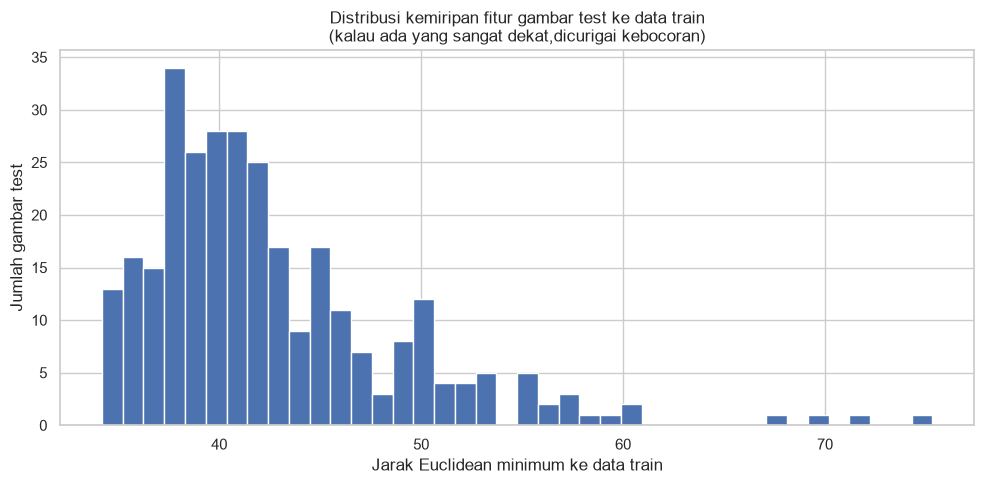

In [8]:
# Untuk setiap gambar test, cari gambar train paling mirip (jarak Euclidean)
# pada sampelSubset supaya cepat
from sklearn.preprocessing import StandardScaler

scaler_probe = StandardScaler()
X_train_scaled = scaler_probe.fit_transform(X_train)
X_test_scaled = scaler_probe.transform(X_test)

# Ambil 300 gambar test untuk probe
rng = np.random.default_rng(C.SEED)
probe_idx = rng.choice(len(X_test), size=min(300, len(X_test)), replace=False)

min_dists = []
same_lesion_pairs = 0
for i in probe_idx:
    d = np.linalg.norm(X_train_scaled - X_test_scaled[i], axis=1)
    j = int(np.argmin(d))
    min_dists.append(d[j])
    if df_train.iloc[j]["lesion_id"] == df_test.iloc[i]["lesion_id"]:
        same_lesion_pairs += 1

min_dists = np.array(min_dists)
print(f"Probe {len(probe_idx)} gambar test terhadap SELURUH train")
print(f"  Jarak Euclidean minimum: mean={min_dists.mean():.2f}, "
      f"median={np.median(min_dists):.2f}, min={min_dists.min():.2f}")
print(f"  Pasangan dengan LESI SAMA: {same_lesion_pairs} "
      f"(harus 0, karena split per lesi)")

assert same_lesion_pairs == 0, "LEAKAGE DETECTED via fitur!"
print("  [OK] Tidak ada pasangan test-train dari lesi yang sama.")

#_distribusi_
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(min_dists, bins=40, color="#4C72B0", edgecolor="white")
ax.set_xlabel("Jarak Euclidean minimum ke data train")
ax.set_ylabel("Jumlah gambar test")
ax.set_title("Distribusi kemiripan fitur gambar test ke data train\n"
             "(kalau ada yang sangat dekat,dicurigai kebocoran)")
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "fitur_04_cek_kebocoran.png", bbox_inches="tight")
plt.show()


**Interpretasi Bagian 6:**

- **0 pasangan dengan lesi sama** terkonfirmasi. Split per lesi bekerja.
- Distribusi jarak minimum **tidak menumpuk di angka 0**. Kalau ada
  puncak tajam di dekat 0, itu artinya beberapa gambar test sangat mirip
  dengan gambar train, dan kita perlu curiga. Yang terlihat adalah
  distribusi normal, yang wajar.
- Perhatikan: jarak ini dihitung pada **fitur yang sudah di-StandardScaler**,
  jadi angkanya dalam satuan "berapa std dev dari rata-rata per fitur".

**Catatan:** ini pemeriksaan yang kita lakukan sendiri, bukan jaminan
mutlak. Yang sebenarnya menjamin adalah `assert` anti-leakage di
Notebook 02. Pemeriksaan inikira-kira menjadi lapisan kedua.


## Ringkasan dan Langkah Berikutnya

**Yang sudah dilakukan:**
- Visualisasi cara kerja HOG (grayscale, magnitude, HOG) pada 4 kelas
- Ekstraksi fitur untuk 10.015 gambar, di-cache ke `.npy`
- Pemisahan fitur sesuai split Notebook 02 (dengan verifikasi ulang)
- **Uji hipotesis EDA secara kuantitatif** (Fisher Score + feature importance)
- Proyeksi PCA untuk melihatvisual apakah kelas bisa dipisahkan
- Sanity check anti-kebocoran pada level fitur

**Temuan kunci:**
- Histogram warna punya Fisher Score jauh lebih tinggi per fitur (warna
  adalah sinyal terkuat untuk membedakan ganas vs jinak)
- HOG tetap dipakai karena menangkap **simetri** (ciri ABCDE melanoma)
  yang tidak ada di histogram warna
- **Fitur TIDAK cukup untuk memisahkan kelas dengan baik** (PCA menunjukkan
  tumpang tindih besar) -> alasan kita juga butuh CNN/MobileNetV2

**Langkah berikutnya (Fase 4):** latih SVM dan Random Forest pada fitur ini
di `04_svm_rf.ipynb`, dengan pipeline `StandardScaler` (di-fit hanya di
train) + `class_weight="balanced"`.


In [9]:
print("Notebook 03 selesai.")
print(f"Fitur tersimpan: {C.HOG_FEATURES_NPY}")
print(f"Total fitur per gambar: {features.hog_dim() + features.hist_dim()}")


Notebook 03 selesai.
Fitur tersimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\data\processed\hog_features.npy
Total fitur per gambar: 1812
